# Transfer Learning with VGG16

This notebook evaluates a transfer-learning approach using a frozen ImageNet-pretrained VGG16 backbone on the same patient-grouped CBIS-DDSM split used for the corrected baseline CNN. The model is compared with the baseline using default and recall-oriented decision thresholds.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

DATASET_DIR = os.environ.get(
    "CBIS_DDSM_DIR",
    os.path.join("..", "data", "CBIS-DDSM")
)

CSV_DIR = os.path.join(DATASET_DIR, "csv")
JPEG_DIR = os.path.join(DATASET_DIR, "jpeg")

print("CSV folder exists:", os.path.exists(CSV_DIR))
print("JPEG folder exists:", os.path.exists(JPEG_DIR))
print("CSV files:", os.listdir(CSV_DIR))

CSV folder exists: True
JPEG folder exists: True
CSV files: ['calc_case_description_test_set.csv', 'calc_case_description_train_set.csv', 'dicom_info.csv', 'mass_case_description_test_set.csv', 'mass_case_description_train_set.csv', 'meta.csv']


In [2]:
train_mass = pd.read_csv(
    os.path.join(CSV_DIR, "mass_case_description_train_set.csv")
)

print("Rows:", len(train_mass))
print("\nColumns:")
print(train_mass.columns.tolist())

Rows: 1318

Columns:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


In [3]:
print(train_mass["pathology"].value_counts())

pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64


In [4]:
train_mass["label"] = train_mass["pathology"].apply(
    lambda x: 1 if x == "MALIGNANT" else 0
)

print(train_mass[["pathology", "label"]].head())
print("\nBinary label distribution:")
print(train_mass["label"].value_counts())

   pathology  label
0  MALIGNANT      1
1  MALIGNANT      1
2     BENIGN      0
3     BENIGN      0
4     BENIGN      0

Binary label distribution:
label
0    681
1    637
Name: count, dtype: int64


The pathology labels were converted into binary classes, where malignant cases were assigned a label of 1 and benign cases (including benign without callback) were assigned a label of 0. The resulting dataset contained 637 malignant samples and 681 benign samples, indicating a relatively balanced class distribution suitable for supervised learning.

In [5]:
print(train_mass["image file path"].iloc[0])

Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm


In [6]:
for root, dirs, files in os.walk(JPEG_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))

    if len(files) > 0:
        print("First 5 files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg
Number of files: 0
Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Number of files: 2
First 5 files: ['1-263.jpg', '2-241.jpg']


In [7]:
dicom_info = pd.read_csv(os.path.join(CSV_DIR, "dicom_info.csv"))

print("Rows:", len(dicom_info))
print("\nColumns:")
print(dicom_info.columns.tolist())

print("\nFirst 3 rows:")
display(dicom_info.head(3))

Rows: 10237

Columns:
['file_path', 'image_path', 'AccessionNumber', 'BitsAllocated', 'BitsStored', 'BodyPartExamined', 'Columns', 'ContentDate', 'ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber', 'LargestImagePixelValue', 'Laterality', 'Modality', 'PatientBirthDate', 'PatientID', 'PatientName', 'PatientOrientation', 'PatientSex', 'PhotometricInterpretation', 'PixelRepresentation', 'ReferringPhysicianName', 'Rows', 'SOPClassUID', 'SOPInstanceUID', 'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer', 'SecondaryCaptureDeviceManufacturerModelName', 'SeriesDescription', 'SeriesInstanceUID', 'SeriesNumber', 'SmallestImagePixelValue', 'SpecificCharacterSet', 'StudyDate', 'StudyID', 'StudyInstanceUID', 'StudyTime']

First 3 rows:


,file_path,image_path,AccessionNumber,BitsAllocated,BitsStored,BodyPartExamined,Columns,ContentDate,ContentTime,ConversionType,...,SecondaryCaptureDeviceManufacturerModelName,SeriesDescription,SeriesInstanceUID,SeriesNumber,SmallestImagePixelValue,SpecificCharacterSet,StudyDate,StudyID,StudyInstanceUID,StudyTime
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,NaN,16,16,BREAST,351,20160426,131732.685,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.129308726812851964007...,1,23078,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.271867287611061855725...,214951.0
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,NaN,16,16,BREAST,3526,20160426,143829.101,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.248386742010678582309...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.161516517311681906612...,193426.0
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,NaN,16,16,BREAST,1546,20160503,111956.298,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.267213171011171858918...,1,0,ISO_IR 100,20160807.0,DDSM,1.3.6.1.4.1.9590.100.1.2.291043622711253836701...,161814.0


In [8]:
dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.38118...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187...,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.15333...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.15333...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339...,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.17899...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.17899...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994...,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.41183...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833...,ROI mask images


In [9]:
pd.set_option("display.max_colwidth", None)

display(
    dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)
)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.jpg,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.jpg,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.jpg,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.jpg,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.jpg,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.jpg,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.jpg,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.jpg,ROI mask images


In [10]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Number of full mammograms:", len(full_mammo))

display(
    full_mammo[["image_path"]].head(5)
)

Number of full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
Exists: True


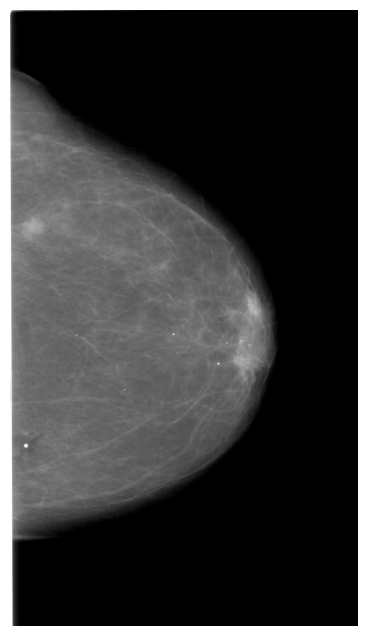

Image size: (3526, 6256)


In [11]:
sample_path = r"CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg"

full_path = os.path.join(
    DATASET_DIR,
    sample_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
)

print(full_path)
print("Exists:", os.path.exists(full_path))

img = Image.open(full_path)

plt.figure(figsize=(8,8))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

print("Image size:", img.size)

In [12]:
sizes = []

for root, dirs, files in os.walk(JPEG_DIR):
    for file in files:
        if file.endswith(".jpg"):
            path = os.path.join(root, file)

            try:
                img = Image.open(path)
                sizes.append(img.size)
            except:
                pass

            if len(sizes) >= 100:
                break

    if len(sizes) >= 100:
        break

print("First 10 image sizes:")
print(sizes[:10])

print("\nUnique sizes found:")
print(set(sizes))

First 10 image sizes:
[(226, 211), (2626, 5056), (3826, 6601), (4126, 5491), (3151, 5491), (89, 81), (4072, 5728), (2952, 4504), (3480, 5992), (2568, 4648)]

Unique sizes found:
{(497, 537), (3056, 4528), (2912, 4544), (2626, 4996), (3096, 4664), (3904, 5640), (3360, 5912), (370, 327), (453, 407), (2568, 4648), (3416, 6032), (262, 247), (305, 401), (265, 209), (553, 441), (226, 211), (438, 448), (292, 229), (756, 913), (3048, 4576), (436, 386), (2807, 4595), (2888, 4504), (3151, 5491), (2506, 4741), (249, 233), (417, 409), (2992, 4616), (4081, 6691), (3544, 6032), (449, 459), (2281, 5296), (2926, 5491), (2904, 4176), (3968, 5712), (2491, 5206), (2616, 4712), (3072, 4544), (129, 145), (2896, 4672), (761, 785), (289, 225), (2731, 5236), (4426, 6511), (89, 81), (4024, 5704), (191, 266), (3280, 5896), (3136, 6526), (2566, 5296), (3712, 5584), (1846, 4006), (304, 310), (273, 249), (2952, 4504), (2512, 4760), (4136, 5840), (4126, 5491), (2341, 5326), (2664, 4720), (3992, 5768), (2911, 5491),

In [13]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammogram rows:", len(full_mammo))

sizes = []

for _, row in full_mammo.head(100).iterrows():

    img_path = row["image_path"]

    img_path = img_path.replace(
        "CBIS-DDSM/jpeg/",
        "jpeg/"
    )

    full_path = os.path.join(DATASET_DIR, img_path)

    try:
        img = Image.open(full_path)
        sizes.append(img.size)
    except:
        pass

print("Unique sizes among first 100 full mammograms:")
print(set(sizes))

Full mammogram rows: 2857
Unique sizes among first 100 full mammograms:
{(3056, 4464), (2456, 4704), (3136, 4664), (2056, 5041), (2840, 4632), (3704, 5704), (2824, 4696), (1981, 4876), (2864, 4424), (2912, 4592), (3496, 5491), (2960, 4712), (2712, 4784), (2664, 4744), (4501, 6871), (2808, 4544), (3008, 4480), (3080, 4560), (2671, 5896), (3032, 4520), (3136, 4696), (1872, 4736), (4040, 5648), (3631, 6706), (3128, 4728), (2851, 5011), (4256, 6032), (3481, 5971), (4056, 5768), (2941, 5221), (2888, 4568), (2432, 4672), (2926, 5491), (3088, 4760), (3112, 4824), (3466, 5386), (2472, 4720), (3224, 5944), (2728, 4752), (3256, 5976), (2371, 5491), (3886, 6271), (3104, 4624), (2896, 4528), (3040, 4496), (2728, 4736), (2936, 4448), (3528, 5976), (2712, 4712), (3091, 6676), (4048, 5752), (2840, 4672), (3048, 5912), (3526, 6256), (3106, 6466), (2624, 4608), (4072, 5920), (4306, 6871), (3361, 5206), (3720, 5752), (4088, 5864), (4048, 5864), (2911, 5491), (2326, 5356), (2752, 4680), (2784, 4568), (35

## Image Resizing Rationale

All mammograms were resized to 224 x 224 pixels to provide a consistent input size and reduce computational requirements during training. This resolution also matches the standard input dimensions used by VGG16, allowing the transfer-learning model to use the same spatial resolution as the baseline CNN.

In [14]:
print(train_mass.columns.tolist())

['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path', 'label']


In [15]:
train_mass[[
    "image file path",
    "label"
]].head()

,image file path,label
0,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm,1
1,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm,1
2,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.347107867812656628709864319310977895697/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/000000.dcm,0
3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.272600286511817402806912403581910920939/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/000000.dcm,0
4,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.174047308712169195014610267031196524486/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/000000.dcm,0


In [16]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammograms:", len(full_mammo))

full_mammo[["image_path"]].head()

Full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


In [17]:
print(full_mammo["image_path"].iloc[0])

CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg


In [18]:
meta = pd.read_csv(
    os.path.join(CSV_DIR, "meta.csv")
)

print(meta.head())
print("\n")
print(meta.columns.tolist())

                                                  SeriesInstanceUID  \
0  1.3.6.1.4.1.9590.100.1.2.117041576511324414842508325652101471266   
1   1.3.6.1.4.1.9590.100.1.2.43873839610761788013224723323225482381   
2   1.3.6.1.4.1.9590.100.1.2.76741674113167646338262765132488965294   
3  1.3.6.1.4.1.9590.100.1.2.296931352612305599800425693833437698626   
4   1.3.6.1.4.1.9590.100.1.2.43665767012035310007732414810147712942   

                                                   StudyInstanceUID Modality  \
0  1.3.6.1.4.1.9590.100.1.2.229361142710768138411679379233064924540       MG   
1  1.3.6.1.4.1.9590.100.1.2.195593486612988388325770883972107282733       MG   
2  1.3.6.1.4.1.9590.100.1.2.257901172612530623323924356380431605062       MG   
3  1.3.6.1.4.1.9590.100.1.2.109468616710242115222536802734027827120       MG   
4  1.3.6.1.4.1.9590.100.1.2.380627129513562450304304820723973964760       MG   

  SeriesDescription BodyPartExamined  SeriesNumber Collection  Visibility  \
0   ROI mask im

In [19]:
for root, dirs, files in os.walk(JPEG_DIR):
    if files:
        print("Folder:", root)
        print("Files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Files: ['1-263.jpg', '2-241.jpg']


In [20]:
sample_folder = os.path.join(
    JPEG_DIR,
    os.listdir(JPEG_DIR)[0]
)

print("Sample folder:")
print(sample_folder)

print("\nFiles inside:")
print(os.listdir(sample_folder))

Sample folder:
C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132

Files inside:
['1-263.jpg', '2-241.jpg']


In [21]:
print(train_mass["image file path"].iloc[0])

Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm


In [22]:
print(train_mass["image file path"].iloc[1])

Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm


In [23]:
uid = "1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515"

matches = dicom_info[
    dicom_info["image_path"].str.contains(uid, na=False)
]

print("Matches found:", len(matches))

if len(matches) > 0:
    display(matches[[
        "image_path",
        "SeriesDescription"
    ]].head())

Matches found: 1


,image_path,SeriesDescription
7774,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,full mammogram images


In [24]:
def get_jpeg_path_from_dicom_path(dicom_path):
    parts = dicom_path.split("/")
    
    # The second UID folder maps to the JPEG image in dicom_info
    target_uid = parts[-2]
    
    matches = dicom_info[
        dicom_info["image_path"].str.contains(target_uid, na=False)
    ]
    
    # Prefer full mammogram images
    matches = matches[
        matches["SeriesDescription"] == "full mammogram images"
    ]
    
    if len(matches) == 0:
        return None
    
    jpeg_relative_path = matches.iloc[0]["image_path"]
    jpeg_relative_path = jpeg_relative_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
    
    return os.path.join(DATASET_DIR, jpeg_relative_path)

In [25]:
test_path = get_jpeg_path_from_dicom_path(
    train_mass["image file path"].iloc[0]
)

print(test_path)
print("Exists:", os.path.exists(test_path))
print("Label:", train_mass["label"].iloc[0])

C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg
Exists: True
Label: 1


In [26]:
train_mass["jpeg_path"] = train_mass["image file path"].apply(
    get_jpeg_path_from_dicom_path
)

print("Total rows:", len(train_mass))
print("Rows with valid JPEG paths:", train_mass["jpeg_path"].notna().sum())
print("Rows missing JPEG paths:", train_mass["jpeg_path"].isna().sum())

train_dataset = train_mass[
    train_mass["jpeg_path"].notna()
][["jpeg_path", "label", "pathology"]].copy()

display(train_dataset.head())

Total rows: 1318
Rows with valid JPEG paths: 1318
Rows missing JPEG paths: 0


,jpeg_path,label,pathology
0,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,1,MALIGNANT
1,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg,1,MALIGNANT
2,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg,0,BENIGN
3,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg,0,BENIGN
4,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg,0,BENIGN


# Create train/validation split

In [27]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_dataset,
    test_size=0.2,
    random_state=42,
    stratify=train_dataset["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

Training samples: 1054
Validation samples: 264

Training label distribution:
label
0    545
1    509
Name: count, dtype: int64

Validation label distribution:
label
0    136
1    128
Name: count, dtype: int64


Label: 1
Image: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.396178191110460835408694483283901250731/1-253.jpg
Original size: (2624, 4752)


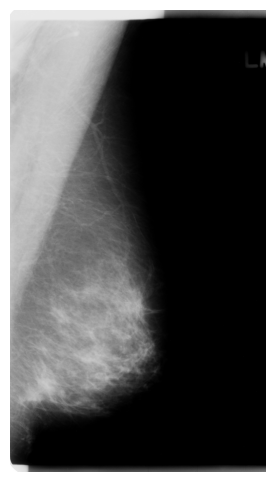

In [28]:
# load one image

sample_path = train_df.iloc[0]["jpeg_path"]

print("Label:", train_df.iloc[0]["label"])
print("Image:", sample_path)

img = Image.open(sample_path)

print("Original size:", img.size)

plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

Original size: (2624, 4752)
Resized size: (224, 224)


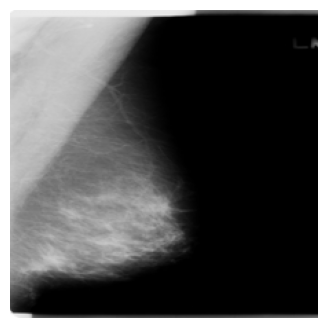

In [29]:
# resize one image

resized = img.resize((224, 224))

print("Original size:", img.size)
print("Resized size:", resized.size)

plt.figure(figsize=(4,4))
plt.imshow(resized, cmap="gray")
plt.axis("off")
plt.show()

In [30]:
# normalize the image

img_array = np.array(resized)

print("Before normalization:")
print("Shape:", img_array.shape)
print("Min pixel:", img_array.min())
print("Max pixel:", img_array.max())

img_array = img_array / 255.0

print("\nAfter normalization:")
print("Shape:", img_array.shape)
print("Min pixel:", img_array.min())
print("Max pixel:", img_array.max())

Before normalization:
Shape: (224, 224)
Min pixel: 0
Max pixel: 255

After normalization:
Shape: (224, 224)
Min pixel: 0.0
Max pixel: 1.0


In [31]:
# create a reusable preprocessing function

IMG_SIZE = (224, 224)

def load_and_preprocess_image(image_path):
    img = Image.open(image_path).convert("L")  # grayscale
    img = img.resize(IMG_SIZE)
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=-1)  # shape: 224, 224, 1
    return img_array

In [32]:
sample_processed = load_and_preprocess_image(train_df.iloc[0]["jpeg_path"])

print("Processed image shape:", sample_processed.shape)
print("Min pixel:", sample_processed.min())
print("Max pixel:", sample_processed.max())

Processed image shape: (224, 224, 1)
Min pixel: 0.0
Max pixel: 1.0


In [33]:
# process the entire dataset

X_train = np.array([
    load_and_preprocess_image(path)
    for path in train_df["jpeg_path"]
])

y_train = train_df["label"].values

X_val = np.array([
    load_and_preprocess_image(path)
    for path in val_df["jpeg_path"]
])

y_val = val_df["label"].values

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation images:", X_val.shape)
print("Validation labels:", y_val.shape)

Training images: (1054, 224, 224, 1)
Training labels: (1054,)

Validation images: (264, 224, 224, 1)
Validation labels: (264,)


## Prepare images for VGG16

VGG16 expects three-channel image inputs. The grayscale mammograms are therefore replicated across three channels without changing their visual content.

In [34]:
X_train_rgb = np.repeat(X_train, 3, axis=-1)
X_val_rgb = np.repeat(X_val, 3, axis=-1)

print("VGG16 training images:", X_train_rgb.shape)
print("VGG16 validation images:", X_val_rgb.shape)

VGG16 training images: (1054, 224, 224, 3)
VGG16 validation images: (264, 224, 224, 3)


## Load the pre-trained VGG16 base

The convolutional base is loaded with ImageNet weights and its original classification head is excluded. All pre-trained layers are initially frozen so that only the new mammography classification head will be trained.

In [35]:
from tensorflow.keras.applications import VGG16

vgg16_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base.trainable = False

print("VGG16 base loaded successfully")
print("Trainable layers:", len(vgg16_base.trainable_weights))
print("Non-trainable layers:", len(vgg16_base.non_trainable_weights))

VGG16 base loaded successfully
Trainable layers: 0
Non-trainable layers: 26


## Build the VGG16 classification model

A lightweight classification head is added on top of the frozen VGG16 convolutional base for binary benign-versus-malignant classification.

In [36]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

vgg16_model = Sequential([
    vgg16_base,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

vgg16_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Compile the frozen-base model

The model is compiled for binary classification using Adam optimisation, binary cross-entropy loss, and clinically relevant evaluation metrics.

In [37]:
import tensorflow as tf
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

print("VGG16 model compiled successfully")

VGG16 model compiled successfully


## Training configuration

Early stopping is used to stop training when the validation loss no longer improves and to restore the best-performing weights.

In [38]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early stopping configured")

Early stopping configured


## Train the frozen-base VGG16 model

The VGG16 convolutional base remains frozen while the new classification head is trained on the mammography dataset.

In [39]:
history_vgg16 = vgg16_model.fit(
    X_train_rgb,
    y_train,
    validation_data=(X_val_rgb, y_val),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 54s 800ms/step - accuracy: 0.5104 - loss: 0.7347 - precision: 0.4928 - recall: 0.4715 - roc_auc: 0.5057 - val_accuracy: 0.5947 - val_loss: 0.6873 - val_precision: 0.5587 - val_recall: 0.7812 - val_roc_auc: 0.6031
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 52s 783ms/step - accuracy: 0.5161 - loss: 0.7195 - precision: 0.4989 - recall: 0.4538 - roc_auc: 0.5191 - val_accuracy: 0.5871 - val_loss: 0.6861 - val_precision: 0.5508 - val_recall: 0.8047 - val_roc_auc: 0.6114
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 52s 782ms/step - accuracy: 0.5123 - loss: 0.7187 - precision: 0.4945 - recall: 0.4440 - roc_auc: 0.5174 - val_accuracy: 0.5492 - val_loss: 0.6830 - val_precision: 0.5464 - val_recall: 0.4141 - val_roc_auc: 0.6129
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 51s 781ms/step - accuracy: 0.5256 - loss: 0.7086 - precision: 0.5098 - recall: 0.4617 - roc_auc: 0.5294 - val_accuracy: 0.5909 - val_loss: 0.6848 - val_precision: 0.5472 - val_recall: 0.9062 - val_roc_auc: 0.6

### Limitation of the initial dataset split

This initial experiment reused the row-level stratified split developed for the feature prototype. A subsequent dataset audit found that multiple metadata records could refer to the same patient or full mammogram. Consequently, the initial split contained patient overlap and duplicate mammograms across the training and validation partitions.

A small number of full mammograms were also associated with conflicting pathology labels because the source metadata describes individual abnormalities rather than assigning one unambiguous label to every full image.

The results from this experiment are therefore retained as exploratory prototype results and are not treated as an independent estimate of generalisation to unseen patients. Subsequent experiments will use an image-deduplicated, patient-grouped split with an explicit policy for conflicting labels.

# Patient-grouped VGG16 experiment

This section retrains VGG16 using the patient-grouped, image-deduplicated split prepared for the corrected experiments. The split contains no overlapping patients or duplicate mammograms between training and validation sets.

In [40]:
split_dir = "Splits"

dataset_root = os.environ.get(
    "CBIS_DDSM_DIR",
    os.path.join("..", "data", "CBIS-DDSM")
)

train_grouped_df = pd.read_csv(
    os.path.join(split_dir, "train_patient_grouped.csv")
)

val_grouped_df = pd.read_csv(
    os.path.join(split_dir, "val_patient_grouped.csv")
)

train_grouped_df["jpeg_path"] = train_grouped_df["jpeg_path"].apply(
    lambda p: os.path.join(dataset_root, p)
)

val_grouped_df["jpeg_path"] = val_grouped_df["jpeg_path"].apply(
    lambda p: os.path.join(dataset_root, p)
)

print("Training rows:", len(train_grouped_df))
print("Validation rows:", len(val_grouped_df))

print(
    "Training paths found:",
    train_grouped_df["jpeg_path"].apply(os.path.exists).sum(),
    "/", len(train_grouped_df)
)

print(
    "Validation paths found:",
    val_grouped_df["jpeg_path"].apply(os.path.exists).sum(),
    "/", len(val_grouped_df)
)

Training rows: 984
Validation rows: 241
Training paths found: 984 / 984
Validation paths found: 241 / 241


## Prepare patient-grouped images for VGG16

The patient-grouped mammograms are loaded as grayscale images, resized to 224 x 224, replicated across three channels, and processed using VGG16's ImageNet preprocessing function.

In [41]:
from tensorflow.keras.applications.vgg16 import preprocess_input

def load_vgg16_image(path):
    image = Image.open(path).convert("L")
    image = image.resize((224, 224))
    image = np.array(image, dtype=np.float32)

    # Replicate grayscale image across three channels
    image = np.repeat(image[..., np.newaxis], 3, axis=-1)

    # Apply VGG16 ImageNet preprocessing
    image = preprocess_input(image)

    return image

In [42]:
X_train_grouped_vgg = np.array([
    load_vgg16_image(path)
    for path in train_grouped_df["jpeg_path"]
], dtype=np.float32)

X_val_grouped_vgg = np.array([
    load_vgg16_image(path)
    for path in val_grouped_df["jpeg_path"]
], dtype=np.float32)

y_train_grouped = train_grouped_df["label"].to_numpy(dtype=np.float32)
y_val_grouped = val_grouped_df["label"].to_numpy(dtype=np.float32)

print("Training images:", X_train_grouped_vgg.shape)
print("Training labels:", y_train_grouped.shape)

print("\nValidation images:", X_val_grouped_vgg.shape)
print("Validation labels:", y_val_grouped.shape)

print("\nTraining dtype:", X_train_grouped_vgg.dtype)
print("Validation dtype:", X_val_grouped_vgg.dtype)

Training images: (984, 224, 224, 3)
Training labels: (984,)

Validation images: (241, 224, 224, 3)
Validation labels: (241,)

Training dtype: float32
Validation dtype: float32


In [43]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import VGG16

vgg16_grouped_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_grouped_base.trainable = False

vgg16_grouped_model = Sequential([
    vgg16_grouped_base,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

vgg16_grouped_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [44]:
vgg16_grouped_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

print("Patient-grouped VGG16 model compiled successfully")

Patient-grouped VGG16 model compiled successfully


In [45]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_vgg16_grouped = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early stopping configured for patient-grouped VGG16")

Early stopping configured for patient-grouped VGG16


In [46]:
history_vgg16_grouped = vgg16_grouped_model.fit(
    X_train_grouped_vgg,
    y_train_grouped,
    validation_data=(X_val_grouped_vgg, y_val_grouped),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop_vgg16_grouped]
)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 47s 750ms/step - accuracy: 0.4705 - loss: 1.5050 - precision: 0.4617 - recall: 0.5418 - roc_auc: 0.4756 - val_accuracy: 0.5228 - val_loss: 0.8305 - val_precision: 0.5106 - val_recall: 0.6102 - val_roc_auc: 0.5300
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 46s 743ms/step - accuracy: 0.5061 - loss: 1.1908 - precision: 0.4921 - recall: 0.5188 - roc_auc: 0.4871 - val_accuracy: 0.5394 - val_loss: 0.7720 - val_precision: 0.5267 - val_recall: 0.5847 - val_roc_auc: 0.5423
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 46s 742ms/step - accuracy: 0.5346 - loss: 0.9697 - precision: 0.5203 - recall: 0.5356 - roc_auc: 0.5385 - val_accuracy: 0.5353 - val_loss: 0.7413 - val_precision: 0.5254 - val_recall: 0.5254 - val_roc_auc: 0.5554
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 48s 777ms/step - accuracy: 0.5640 - loss: 0.8548 - precision: 0.5518 - recall: 0.5460 - roc_auc: 0.5844 - val_accuracy: 0.5228 - val_loss: 0.7256 - val_precision: 0.5143 - val_recall: 0.4576 - val_roc_auc: 0.5

### Reproducibility note

Training deep neural networks involves stochastic operations such as weight initialisation, dropout and mini-batch ordering. Consequently, retraining the model may produce different validation metrics.

The evaluation results presented below correspond to the trained VGG16 model used for the final project experiments. The same fixed patient-grouped training and validation split is reused to allow comparison with the corrected baseline CNN.

In [47]:
vgg16_grouped_results = vgg16_grouped_model.evaluate(
    X_val_grouped_vgg,
    y_val_grouped,
    verbose=1,
    return_dict=True
)

print(vgg16_grouped_results)

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5975 - loss: 0.6902 - precision: 0.5929 - recall: 0.5678 - roc_auc: 0.6212
{'accuracy': 0.5975103974342346, 'loss': 0.6902333498001099, 'precision': 0.5929203629493713, 'recall': 0.5677965879440308, 'roc_auc': 0.6211933493614197}


In [48]:
os.makedirs("Models", exist_ok=True)

model_path = os.path.join(
    "Models",
    "vgg16_patient_grouped.keras"
)

vgg16_grouped_model.save(model_path)

print("Corrected VGG16 model saved to:")
print(model_path)

Corrected VGG16 model saved to:
C:\Users\Ivan\Documents\Y3S2 local\FYP\04 Implementation\Models\vgg16_patient_grouped.keras


### Corrected VGG16 evaluation

The VGG16 transfer-learning model was retrained using the same patient-grouped, image-deduplicated split as the corrected baseline CNN. VGG16-specific ImageNet preprocessing was applied before training.

Validation performance:
- Accuracy: 59.75%
- Precision: 59.29%
- Recall: 56.78%
- ROC-AUC: 0.6212
- Loss: 0.6902

Compared with the corrected baseline CNN, VGG16 achieved slightly higher recall but lower accuracy and ROC-AUC. The result suggests that transfer learning provides a modest sensitivity improvement, although it does not clearly outperform the baseline across all metrics.

In [1]:
from tensorflow.keras.models import load_model

vgg16_grouped_model = load_model(model_path)

print("Corrected VGG16 model loaded successfully.")

NameError: name 'model_path' is not defined

In [2]:
from pathlib import Path
from tensorflow.keras.applications.vgg16 import preprocess_input

val_split_path = os.path.join(
    split_dir,
    "val_patient_grouped.csv"
)

dataset_root = Path(dataset_root)

val_df = pd.read_csv(val_split_path)

def load_vgg16_image(relative_path):
    image_path = dataset_root / relative_path

    image = Image.open(image_path).convert("L")
    image = image.resize((224, 224))

    image = np.array(image, dtype=np.float32)

    # Replicate grayscale image across 3 channels
    image = np.repeat(image[..., np.newaxis], 3, axis=-1)

    # Apply VGG16 ImageNet preprocessing
    image = preprocess_input(image)

    return image

X_val_vgg = np.stack([
    load_vgg16_image(path)
    for path in val_df["jpeg_path"]
])

y_val_vgg = val_df["label"].to_numpy(dtype=np.int32)

print("X_val_vgg shape:", X_val_vgg.shape)
print("y_val_vgg shape:", y_val_vgg.shape)
print("X_val_vgg dtype:", X_val_vgg.dtype)
print("y_val_vgg dtype:", y_val_vgg.dtype)
print("Label counts:", np.bincount(y_val_vgg))

X_val_vgg shape: (241, 224, 224, 3)
y_val_vgg shape: (241,)
X_val_vgg dtype: float32
y_val_vgg dtype: int32
Label counts: [123 118]


In [3]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score
)

# Predict malignant-class probabilities
vgg_val_prob = vgg16_grouped_model.predict(
    X_val_vgg,
    verbose=0
).ravel()

# Convert probabilities to binary predictions using threshold = 0.5
vgg_val_pred = (vgg_val_prob >= 0.5).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val_vgg.astype(int),
    vgg_val_pred
).ravel()

# Additional metrics
vgg_f1 = f1_score(
    y_val_vgg.astype(int),
    vgg_val_pred
)

vgg_specificity = tn / (tn + fp)

print("Confusion matrix values:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print(f"\nF1-score: {vgg_f1:.4f}")
print(f"Specificity: {vgg_specificity:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_val_vgg.astype(int),
        vgg_val_pred,
        target_names=["Benign", "Malignant"],
        digits=4
    )
)

Confusion matrix values:
TN: 77
FP: 46
FN: 51
TP: 67

F1-score: 0.5801
Specificity: 0.6260

Classification report:
              precision    recall  f1-score   support

      Benign     0.6016    0.6260    0.6135       123
   Malignant     0.5929    0.5678    0.5801       118

    accuracy                         0.5975       241
   macro avg     0.5972    0.5969    0.5968       241
weighted avg     0.5973    0.5975    0.5972       241



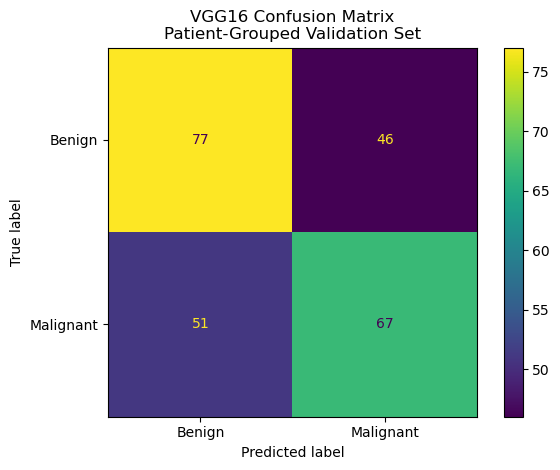

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_vgg = confusion_matrix(
    y_val_vgg.astype(int),
    vgg_val_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_vgg,
    display_labels=["Benign", "Malignant"]
)

disp.plot(values_format="d")
plt.title("VGG16 Confusion Matrix\nPatient-Grouped Validation Set")
plt.tight_layout()
plt.show()

VGG16 ROC-AUC: 0.6211


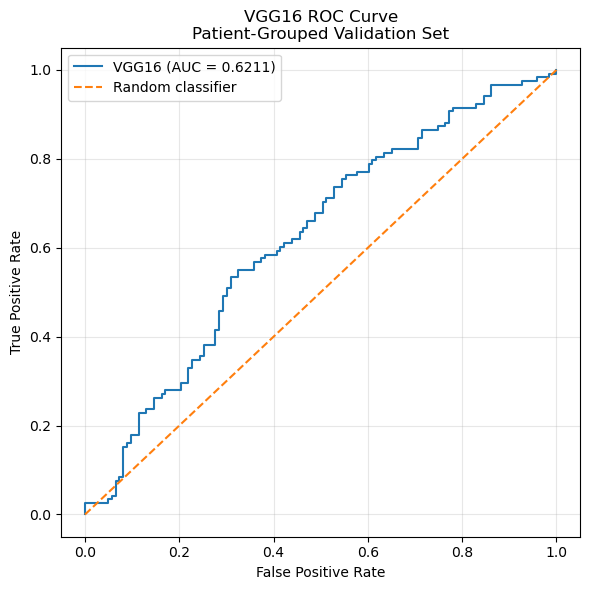

In [5]:
from sklearn.metrics import roc_curve, roc_auc_score

# Compute ROC curve
vgg_fpr, vgg_tpr, vgg_thresholds = roc_curve(
    y_val_vgg.astype(int),
    vgg_val_prob
)

# Compute ROC-AUC
vgg_roc_auc = roc_auc_score(
    y_val_vgg.astype(int),
    vgg_val_prob
)

print(f"VGG16 ROC-AUC: {vgg_roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(6, 6))

plt.plot(
    vgg_fpr,
    vgg_tpr,
    label=f"VGG16 (AUC = {vgg_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("VGG16 ROC Curve\nPatient-Grouped Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_values = np.arange(0.20, 0.81, 0.05)

vgg_threshold_results = []

for threshold in threshold_values:
    preds = (vgg_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_vgg.astype(int),
        preds
    ).ravel()

    accuracy = accuracy_score(y_val_vgg, preds)
    precision = precision_score(y_val_vgg, preds, zero_division=0)
    recall = recall_score(y_val_vgg, preds)
    f1 = f1_score(y_val_vgg, preds)
    specificity = tn / (tn + fp)

    vgg_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity,
        "False Negatives": fn,
        "False Positives": fp
    })

vgg_threshold_df = pd.DataFrame(vgg_threshold_results)

print(
    vgg_threshold_df.round(4).to_string(index=False)
)

 Threshold  Accuracy  Precision  Recall     F1  Specificity  False Negatives  False Positives
      0.20    0.5062     0.4978  0.9746 0.6590       0.0569                3              116
      0.25    0.5311     0.5115  0.9407 0.6627       0.1382                7              106
      0.30    0.5519     0.5250  0.8898 0.6604       0.2276               13               95
      0.35    0.5560     0.5301  0.8220 0.6445       0.3008               21               86
      0.40    0.5892     0.5590  0.7627 0.6452       0.4228               28               71
      0.45    0.5892     0.5674  0.6780 0.6178       0.5041               38               61
      0.50    0.5975     0.5929  0.5678 0.5801       0.6260               51               46
      0.55    0.5851     0.6023  0.4492 0.5146       0.7154               65               35
      0.60    0.5560     0.5846  0.3220 0.4153       0.7805               80               27
      0.65    0.5602     0.6250  0.2542 0.3614       0.8537 

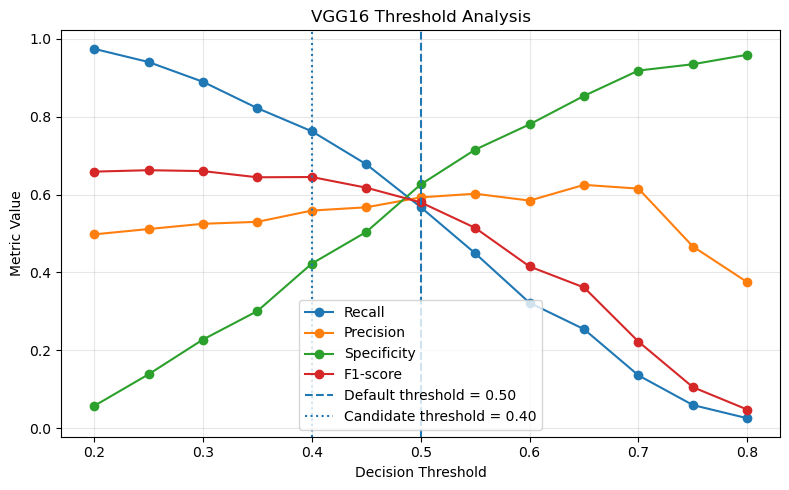

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    vgg_threshold_df["Threshold"],
    vgg_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    vgg_threshold_df["Threshold"],
    vgg_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    vgg_threshold_df["Threshold"],
    vgg_threshold_df["Specificity"],
    marker="o",
    label="Specificity"
)

plt.plot(
    vgg_threshold_df["Threshold"],
    vgg_threshold_df["F1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default threshold = 0.50"
)

plt.axvline(
    x=0.40,
    linestyle=":",
    label="Candidate threshold = 0.40"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.title("VGG16 Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

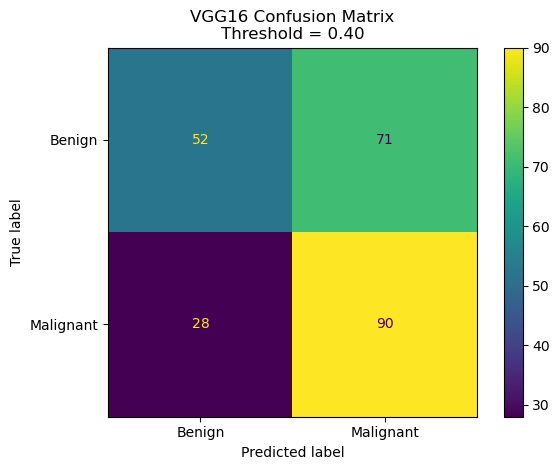

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

vgg_pred_040 = (vgg_val_prob >= 0.40).astype(int)

cm_vgg_040 = confusion_matrix(
    y_val_vgg.astype(int),
    vgg_pred_040
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_vgg_040,
    display_labels=["Benign", "Malignant"]
)

disp.plot(values_format="d")
plt.title("VGG16 Confusion Matrix\nThreshold = 0.40")
plt.tight_layout()
plt.show()

## Comparison of corrected baseline CNN and VGG16

The following table compares both models using the same patient-grouped validation set. Results are shown at the default decision threshold of 0.50 and at the candidate threshold identified during threshold analysis for each model. Candidate thresholds were selected to investigate whether recall could be improved while maintaining a reasonable balance with precision, specificity and F1-score.

In [9]:
comparison_df = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Threshold": 0.50,
        "Accuracy": 0.6141,
        "Precision": 0.6238,
        "Recall": 0.5339,
        "F1": 0.5753,
        "Specificity": 0.6911,
        "ROC-AUC": 0.6324,
        "False Negatives": 55,
        "False Positives": 38
    },
    {
        "Model": "Baseline CNN",
        "Threshold": 0.45,
        "Accuracy": 0.6058,
        "Precision": 0.5762,
        "Recall": 0.7373,
        "F1": 0.6468,
        "Specificity": 0.4797,
        "ROC-AUC": 0.6324,
        "False Negatives": 31,
        "False Positives": 64
    },
    {
        "Model": "VGG16",
        "Threshold": 0.50,
        "Accuracy": 0.5975,
        "Precision": 0.5929,
        "Recall": 0.5678,
        "F1": 0.5801,
        "Specificity": 0.6260,
        "ROC-AUC": 0.6211,
        "False Negatives": 51,
        "False Positives": 46
    },
    {
        "Model": "VGG16",
        "Threshold": 0.40,
        "Accuracy": 0.5892,
        "Precision": 0.5590,
        "Recall": 0.7627,
        "F1": 0.6452,
        "Specificity": 0.4228,
        "ROC-AUC": 0.6211,
        "False Negatives": 28,
        "False Positives": 71
    }
])

print(comparison_df.to_string(index=False))

       Model  Threshold  Accuracy  Precision  Recall     F1  Specificity  ROC-AUC  False Negatives  False Positives
Baseline CNN       0.50    0.6141     0.6238  0.5339 0.5753       0.6911   0.6324               55               38
Baseline CNN       0.45    0.6058     0.5762  0.7373 0.6468       0.4797   0.6324               31               64
       VGG16       0.50    0.5975     0.5929  0.5678 0.5801       0.6260   0.6211               51               46
       VGG16       0.40    0.5892     0.5590  0.7627 0.6452       0.4228   0.6211               28               71


### Interpretation

At the default decision threshold of 0.50, VGG16 achieved slightly higher recall than the baseline CNN, while the baseline achieved higher accuracy, precision, specificity and ROC-AUC.

Threshold analysis showed that sensitivity could be substantially increased by lowering the decision threshold. At a candidate threshold of 0.45, the baseline CNN achieved 73.73% recall with an F1-score of 64.68%. VGG16 achieved the highest recall of 76.27% at a candidate threshold of 0.40, reducing false negatives to 28 compared with 31 for the baseline candidate threshold.

However, the additional sensitivity of VGG16 was accompanied by lower precision and specificity and a greater number of false-positive predictions. The results therefore do not demonstrate clear overall superiority of VGG16. Instead, they illustrate the trade-off between sensitivity and false-positive burden when selecting an operating threshold.

The candidate thresholds were identified using the validation set and should therefore be treated as exploratory operating points rather than final optimised thresholds. Final assessment should apply a predetermined threshold to an independent test set.

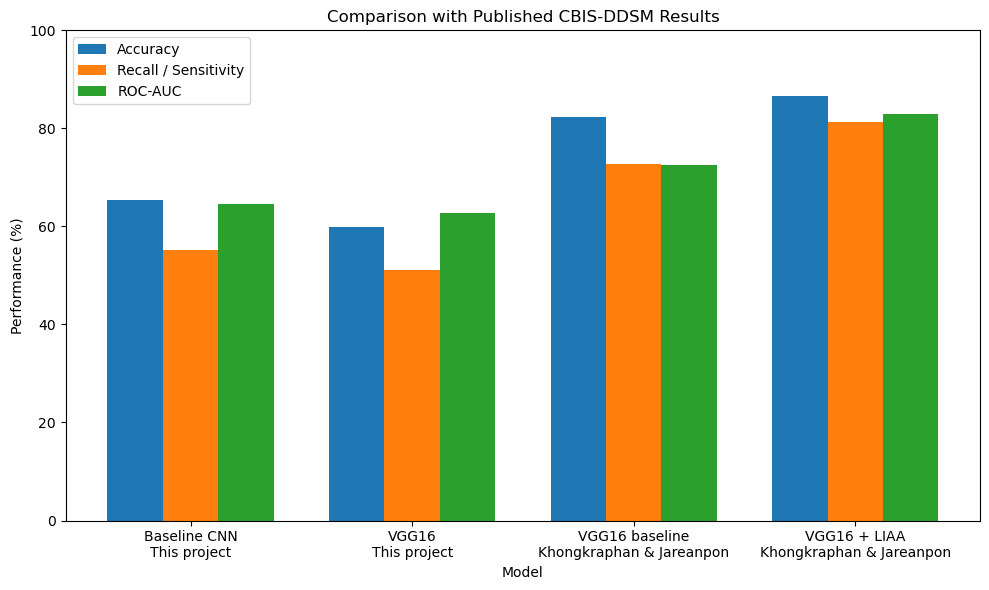

In [1]:
models = [
    "Baseline CNN\nThis project",
    "VGG16\nThis project",
    "VGG16 baseline\nKhongkraphan & Jareanpon",
    "VGG16 + LIAA\nKhongkraphan & Jareanpon"
]

# accuracy = [61.41, 59.75, 82.3, 86.6]
# recall = [53.39, 56.78, 72.7, 81.3]
# roc_auc = [63.24, 62.11, 72.5, 82.9]

accuracy = [65.31, 59.89, 82.3, 86.6]
recall = [55.24, 51.05, 72.7, 81.3]
roc_auc = [64.59, 62.69, 72.5, 82.9]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, accuracy, width, label="Accuracy")
plt.bar(x, recall, width, label="Recall / Sensitivity")
plt.bar(x + width, roc_auc, width, label="ROC-AUC")

plt.ylabel("Performance (%)")
plt.xlabel("Model")
plt.title("Comparison with Published CBIS-DDSM Results")
plt.xticks(x, models)
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()